# 01 - Exploração dos dados

**Objetivo:** entender a estrutura do dataset e diagnosticar problemas de qualidade.


**Lê:** `data/original/*.csv` (baixa do Kaggle automaticamente se não existirem)  
**Gera:** nada (apenas diagnóstico)

In [286]:
import shutil
from pathlib import Path
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

original = Path("../data/original")
original.mkdir(parents=True, exist_ok=True)

if not all((original / f).exists() for f in ["Books.csv" , "Ratings.csv","Users.csv"]):
    import kagglehub
    path = kagglehub.dataset_download("arashnic/book-recommendation-dataset")
    for f in ["Books.csv" , "Ratings.csv","Users.csv"]:
        shutil.copy(Path(path) / f, original / f)
    

print([p.name for p in original.iterdir()])

['Books.csv', 'Ratings.csv', 'Users.csv']


In [287]:
pd.set_option('display.max_columns', None)
original = Path("../data/original")
books= pd.read_csv(original / "Books.csv", low_memory=False)
ratings = pd.read_csv(original / "Ratings.csv")
users = pd.read_csv(original/ "Users.csv")



In [288]:
#filtrando fora as colunas das URLS de imagens
pd.set_option('display.max_columns', None)
books[["ISBN", "Book-Title", "Book-Author", "Year-Of-Publication"]].head()

,ISBN,Book-Title,Book-Author,Year-Of-Publication
0,0195153448,Classical Mythology,Mark P. O. Morford,2002
1,0002005018,Clara Callan,Richard Bruce Wright,2001
2,0060973129,Decision in Normandy,Carlo D'Este,1991
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,1999


In [289]:
pd.set_option('display.max_columns', None)
books.info()
books.isnull().sum() #quase nada

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 271360 entries, 0 to 271359
Data columns (total 8 columns):
 #   Column               Non-Null Count   Dtype 
---  ------               --------------   ----- 
 0   ISBN                 271360 non-null  object
 1   Book-Title           271360 non-null  object
 2   Book-Author          271358 non-null  object
 3   Year-Of-Publication  271360 non-null  object
 4   Publisher            271358 non-null  object
 5   Image-URL-S          271360 non-null  object
 6   Image-URL-M          271360 non-null  object
 7   Image-URL-L          271357 non-null  object
dtypes: object(8)
memory usage: 16.6+ MB


ISBN                   0
Book-Title             0
Book-Author            2
Year-Of-Publication    0
Publisher              2
Image-URL-S            0
Image-URL-M            0
Image-URL-L            3
dtype: int64

In [290]:
pd.set_option('display.max_columns', None)

# visão geral 
print("Books:", books.shape)
print("Ratings:", ratings.shape)
print("Users:", users.shape)

Books: (271360, 8)
Ratings: (1149780, 3)
Users: (278858, 3)


In [291]:
#vendo quais colunas users tem
users.head()

,User-ID,Location,Age
0,1,"nyc, new york, usa",NaN
1,2,"stockton, california, usa",18.0
2,3,"moscow, yukon territory, russia",NaN
3,4,"porto, v.n.gaia, portugal",17.0
4,5,"farnborough, hants, united kingdom",NaN


In [292]:
#verificando quais colunas ratings tem
ratings.head()

,User-ID,ISBN,Book-Rating
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446520802,0
3,276729,052165615X,3
4,276729,0521795028,6


In [293]:
#verificando quais colunas books tem
#books.head()
#books_no_img = books sem as tabelas de imagens
books_no_img = books[["ISBN", "Book-Title", "Book-Author", "Year-Of-Publication"]]
books_no_img.head()

,ISBN,Book-Title,Book-Author,Year-Of-Publication
0,0195153448,Classical Mythology,Mark P. O. Morford,2002
1,0002005018,Clara Callan,Richard Bruce Wright,2001
2,0060973129,Decision in Normandy,Carlo D'Este,1991
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,1999


## Identificação e Tratamento de Inconsistências
Nesta etapa foram mapeadas as inconsistências presentes nos dados e definidas as decisões de tratamento adotadas.


In [294]:
users['Age'].describe() #aqui já é possivel observar um valor impossivel (max 244)

count    168096.000000
mean         34.751434
std          14.428097
min           0.000000
25%          24.000000
50%          32.000000
75%          44.000000
max         244.000000
Name: Age, dtype: float64

In [295]:
users['Age'].unique()

array([ nan,  18.,  17.,  61.,  26.,  14.,  25.,  19.,  46.,  55.,  32.,
        24.,  20.,  34.,  23.,  51.,  31.,  21.,  44.,  30.,  57.,  43.,
        37.,  41.,  54.,  42.,  50.,  39.,  53.,  47.,  36.,  28.,  35.,
        13.,  58.,  49.,  38.,  45.,  62.,  63.,  27.,  33.,  29.,  66.,
        40.,  15.,  60.,   0.,  79.,  22.,  16.,  65.,  59.,  48.,  72.,
        56.,  67.,   1.,  80.,  52.,  69.,  71.,  73.,  78.,   9.,  64.,
       103., 104.,  12.,  74.,  75., 231.,   3.,  76.,  83.,  68., 119.,
        11.,  77.,   2.,  70.,  93.,   8.,   7.,   4.,  81., 114., 230.,
       239.,  10.,   5., 148., 151.,   6., 101., 201.,  96.,  84.,  82.,
        90., 123., 244., 133.,  91., 128.,  94.,  85., 141., 110.,  97.,
       219.,  86., 124.,  92., 175., 172., 209., 212., 237.,  87., 162.,
       100., 156., 136.,  95.,  89., 106.,  99., 108., 210.,  88., 199.,
       147., 168., 132., 159., 186., 152., 102., 116., 200., 115., 226.,
       137., 207., 229., 138., 109., 105., 228., 18

Rodando a célula acima vemos que ambos os extremos sao impossiveis, nenhum recém nascido escreve reviews de livros e ninguém chegou aos 244 anos (ainda).

In [296]:
users['Age'].value_counts().sort_index().tail(50)

Age
116.0    5
118.0    1
119.0    1
123.0    8
124.0    5
127.0    1
128.0    1
132.0    1
133.0    2
136.0    2
137.0    1
138.0    1
140.0    1
141.0    3
143.0    1
146.0    1
147.0    2
148.0    5
151.0    2
152.0    1
156.0    1
157.0    1
159.0    1
162.0    1
168.0    1
172.0    1
175.0    1
183.0    1
186.0    1
189.0    1
199.0    2
200.0    2
201.0    1
204.0    4
207.0    1
208.0    1
209.0    2
210.0    3
212.0    1
219.0    1
220.0    1
223.0    1
226.0    1
228.0    3
229.0    1
230.0    1
231.0    1
237.0    1
239.0    1
244.0    1
Name: count, dtype: int64

Idades acima de 100 aparecem isoladas, a maioria com contagem 1-2 (erro de digitação).
Algumas exceções com contagem levemente maior (123→8, 124→5, 148→5, 116→5), mas
ainda irrelevantes frente ao total de ~168 mil usuários. Confirmando que um filtro de aproximadamente
5-100 é adequado para remover outliers sem perda significativa de dados válidos.


In [297]:
users['Age'].value_counts().sort_index().head(15)

Age
0.0      416
1.0      288
2.0      105
3.0       45
4.0       28
5.0       26
6.0       18
7.0       27
8.0       54
9.0       62
10.0      84
11.0     121
12.0     192
13.0     885
14.0    1962
Name: count, dtype: int64

Idades muito baixas (abaixo de 5 anos) foram descartadas por serem implausíveis
para quem avalia livros. Idades entre 5 e 12 foram mantidas por serem possíveis
(leitores iniciantes, ou avaliações registradas por responsáveis).


In [298]:
books['Year-Of-Publication'].unique()

array(['2002', '2001', '1991', '1999', '2000', '1993', '1996', '1988',
       '2004', '1998', '1994', '2003', '1997', '1983', '1979', '1995',
       '1982', '1985', '1992', '1986', '1978', '1980', '1952', '1987',
       '1990', '1981', '1989', '1984', '0', '1968', '1961', '1958',
       '1974', '1976', '1971', '1977', '1975', '1965', '1941', '1970',
       '1962', '1973', '1972', '1960', '1966', '1920', '1956', '1959',
       '1953', '1951', '1942', '1963', '1964', '1969', '1954', '1950',
       '1967', '2005', '1957', '1940', '1937', '1955', '1946', '1936',
       '1930', '2011', '1925', '1948', '1943', '1947', '1945', '1923',
       '2020', '1939', '1926', '1938', '2030', '1911', '1904', '1949',
       '1932', '1928', '1929', '1927', '1931', '1914', '2050', '1934',
       '1910', '1933', '1902', '1924', '1921', '1900', '2038', '2026',
       '1944', '1917', '1901', '2010', '1908', '1906', '1935', '1806',
       '2021', '2012', '2006', 'DK Publishing Inc', 'Gallimard', '1909',
       

varios anos duplicados como string e int, valores errados (DK Publishing inc e Gallimard), valores muito improvaveis (0, '1376') e alguns impossiveis, (2030, '2037')

In [299]:


print(users["Location"].nunique())
users[users["Location"].str.contains("n/a|,,|^,|,$", case=False, na=False, regex=True)]["Location"].unique()

57339


array(['weston, ,', 'shanghai, n/a, china', 'san sebastian, n/a, spain',
       ..., 'mayagüez, puerto rico,', 'esplugas de llobregat, n/a, spain',
       'stranraer, n/a, united kingdom'], shape=(7198,), dtype=object)

*Location* tem 57339 valores únicos, dos quais 7198 (~12.5%) têm campos vazios ou
"n/a" como texto literal em vez de nulo — ex: "weston, ," (state/country vazios)
ou "shanghai, n/a, china" (state = "n/a" como string).


In [300]:
books['ISBN'].duplicated().sum()

np.int64(0)

Books não possui ISBN duplicado (0 ocorrências) — cada livro é único na tabela,
sem risco de duplicidade em futuros merges com Ratings.

In [301]:
ratings.duplicated(subset=['User-ID', 'ISBN']).sum()

np.int64(0)

No snippet acima verificamos que não teve nenhuma ocorrencia de um usuario avaliando o mesmo livro mais de uma vez




<Axes: xlabel='Book-Rating'>

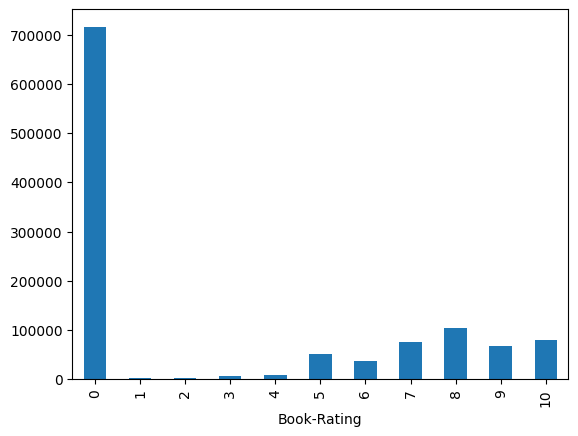

In [302]:
ratings['Book-Rating'].value_counts().sort_index()
ratings['Book-Rating'].value_counts().sort_index().plot(kind='bar')

como é possível ver no resultado do snippet acima, a incidencia da nota 0 é 
extremamente grande, mas isso se deve a forma como o dataset foi montado, nesse caso o zero não significa uma nota zero explicita, significa apenas que o usuario teve interação com o livro mas não o avaliou explicitamente.

In [303]:
isbn_valido = ratings['ISBN'].isin(books['ISBN'])
isbn_valido.value_counts()

ISBN
True     1031136
False     118644
Name: count, dtype: int64

10.3% dos ratings são órfãos (ISBN sem correspondência em Books)



In [304]:
print("", books[books['Book-Title'].str.contains('&amp;', na=False)].shape[0])
print("", books[books['Publisher'].str.contains('&amp;', na=False)].shape[0])

 4870
 15791


*15.791* registros em Publisher e 4.870 em Book-Title contêm a entidade HTML
"&amp;" não decodificada (deveria ser apenas "&"), resultado de um parsing
incorreto do CSV original. Serão substituídos por "&" antes da análise final.

In [305]:
print("Nulos:", books['Book-Author'].isnull().sum())
print("Nome muito curto (<2 chars):", books[books['Book-Author'].str.len() < 2].shape[0])

Nulos: 2
Nome muito curto (<2 chars): 15


Book-Author possui 2 valores nulos e 15 registros com nome suspeitosamente
curto (<2 caracteres) em 271.360 livros — volume irrelevante, sem necessidade
de tratamento robusto. Podem ser descartados ou preenchidos com "Unknown".

In [306]:
print((books['ISBN'] != books['ISBN'].str.strip()).sum())
books[books['ISBN'] != books['ISBN'].str.strip()]

1


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
111808,0486404242\t,War in Kind: And Other Poems (Dover Thrift Edi...,Stephen Crane,1998,Dover Publications,http://images.amazon.com/images/P/0486404242.0...,http://images.amazon.com/images/P/0486404242.0...,http://images.amazon.com/images/P/0486404242.0...


In [307]:
ratings['User-ID'].isin(users['User-ID']).value_counts()

User-ID
True    1149780
Name: count, dtype: int64

Todos os User-ID em Ratings existem em Users (1.149.780/1.149.780) —
nenhum rating órfão por usuário, diferente do que ocorre com ISBN órfão
(10.3% dos ratings referenciam livro inexistente em Books).

In [308]:
books['Publisher'].value_counts().head(10)

Publisher
Harlequin                   7535
Silhouette                  4220
Pocket                      3905
Ballantine Books            3783
Bantam Books                3646
Scholastic                  3160
Simon &amp; Schuster        2971
Penguin Books               2844
Berkley Publishing Group    2771
Warner Books                2727
Name: count, dtype: int64

Publisher.value_counts() não revelou valores genéricos/placeholder no topo —
as editoras mais frequentes são todas legítimas (Harlequin, Silhouette, Pocket,
etc.), confirmando apenas o problema já identificado de "&amp;" não decodificado
(ex: "Simon &amp; Schuster").